# 05 — Fine-tuning 320×320 dan pemilihan submission
Skor leaderboard model 224×224 yang dilaporkan pengguna pada 28 Oktober 2026: **0,85236**. Eksperimen ini melanjutkan checkpoint tersebut pada resolusi lebih tinggi, dengan learning rate rendah dan augmentasi geometri ringan. Split training/validasi dipertahankan.

Tiga kandidat ditetapkan sebelum melihat hasil akhir: model 224, model 320, dan rata-rata probabilitas 50:50. Pemilihan berdasarkan accuracy holdout. Skor ini bukan estimasi CV independen karena holdout juga dipakai memilih checkpoint.

Hasil submission ensemble tahap ini: **0,86491**, dilaporkan pengguna pada 28 Oktober 2026. Eksperimen lanjutan tersedia pada notebook 06.

In [1]:
from pathlib import Path
import sys, json, hashlib
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd() if (Path.cwd() / 'scripts').is_dir() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
RUN = ROOT / 'reports/efficientnet_highres'
display(json.loads((ROOT / 'configs/efficientnet_highres.json').read_text()))
display(pd.read_json(ROOT / 'reports/leaderboard_history.json'))

{'run_name': 'efficientnet_highres',
 'model': 'efficientnet_b0',
 'pretrained': False,
 'init_checkpoint': 'checkpoint/efficientnet_improved/best.pt',
 'image_size': 320,
 'epochs': 6,
 'batch_size': 24,
 'learning_rate': 6e-05,
 'weight_decay': 0.01,
 'label_smoothing': 0.05,
 'patience': 3,
 'seed': 42,
 'validation_fraction': 0.2,
 'workers': 2,
 'threads': 4,
 'amp': True,
 'selection_metric': 'accuracy',
 'geometry': {'degrees': 1.5, 'translate': 0.015, 'scale': 0.03}}

,reported_on,run_name,submission,submission_sha256,score,score_source,leaderboard_partition,metric_name
0,2026-10-27,baseline_cnn,submissions/submission_baseline.csv,5fd9913aedf081fdb66e9823eb28e36e6146162113f3d1...,0.67294,Reported by user in chat,unspecified,unverified
1,2026-10-28,efficientnet_improved,submissions/submission_improved.csv,2b6a2963be747cb4f3eb84e73ec0b162e22864b38e8f80...,0.85236,Reported by user in chat,unspecified,unverified
2,2026-10-28,highres_selection,submissions/submission_highres_selected.csv,9a2231e16ba635ae4f99aa8f74fe8ed5efd46853e856fc...,0.86491,Reported by user in chat,unspecified,unverified


## Inisialisasi dan pencegahan leakage
Checkpoint sumber sudah dilatih pada training split yang sama. Pipeline menolak inisialisasi jika fingerprint data, arsitektur, class mapping, atau ID validasinya berbeda. Optimizer dan cosine schedule dimulai ulang; ini adalah tahap fine-tuning baru, bukan resume optimizer.

Halaman asli di-resize ke 320×320 dengan padding putih. Augmentasi training: rotasi hingga 1,5°, translasi hingga 1,5%, skala 0,97–1,03, serta kontras ringan. Tidak ada flip. Validasi dan inference tidak memakai augmentasi acak. Resolusi, jadwal optimizer, dan augmentasi berubah bersama, sehingga efek masing-masing belum diisolasi.

In [2]:
assert (RUN / 'metrics.json').exists(), 'Jalankan configs/efficientnet_highres.json terlebih dahulu'
from scripts.compare_runs import compare_runs
comparison = compare_runs(candidate='efficientnet_highres', reference='efficientnet_improved')
display(json.loads((RUN / 'run.json').read_text()))
display(pd.read_csv(RUN / 'comparison.csv'))
display(pd.read_csv(RUN / 'history.csv'))

                  run  accuracy  macro_f1  validation_rows  best_epoch
efficientnet_improved  0.854418  0.853316             6395           8
 efficientnet_highres  0.862392  0.861266             6395           5
{
  "reference": "efficientnet_improved",
  "candidate": "efficientnet_highres",
  "identical_split": true,
  "accuracy_gain_percentage_points": 0.797498045347933,
  "macro_f1_gain": 0.007950667588891847,
  "corrected_errors": 232,
  "new_errors": 181,
  "both_correct": 5283,
  "both_wrong": 699,
  "classes_with_f1_improvement": 13,
  "candidate_leaderboard_score": null,
  "recommended_run": "efficientnet_highres"
}


{'config': {'run_name': 'efficientnet_highres',
  'model': 'efficientnet_b0',
  'pretrained': False,
  'init_checkpoint': 'checkpoint/efficientnet_improved/best.pt',
  'image_size': 320,
  'epochs': 6,
  'batch_size': 24,
  'learning_rate': 6e-05,
  'weight_decay': 0.01,
  'label_smoothing': 0.05,
  'patience': 3,
  'seed': 42,
  'validation_fraction': 0.2,
  'workers': 2,
  'threads': 4,
  'amp': True,
  'selection_metric': 'accuracy',
  'geometry': {'degrees': 1.5, 'translate': 0.015, 'scale': 0.03}},
 'device': 'cuda',
 'versions': {'torch': '2.11.0+cu128',
  'numpy': '2.3.5',
  'pandas': '2.3.3',
  'scikit-learn': '1.7.2',
  'Pillow': '12.3.0',
  'matplotlib': '3.10.7',
  'torchvision': '0.26.0+cu128'},
 'initialization': {'path': 'checkpoint/efficientnet_improved/best.pt',
  'sha256': 'd8d9c6d97f01e5d982f182afdeba3b2496b514e062d0e1087dcddfdb153e1e7b',
  'source_epoch': 8,
  'optimizer_reset': True},
 'device_name': 'NVIDIA GeForce RTX 4050 Laptop GPU',
 'train_rows': 25607,
 'vali

,run,accuracy,macro_f1,validation_rows,best_epoch
0,efficientnet_improved,0.854418,0.853316,6395,8
1,efficientnet_highres,0.862392,0.861266,6395,5


,epoch,train_loss,val_loss,accuracy,macro_f1,learning_rate,seconds
0,1,0.686491,0.554737,0.850195,0.849131,0.000060,205.989050
1,2,0.587570,0.537196,0.857545,0.856532,0.000056,149.331091
2,3,0.534045,0.532117,0.860829,0.859502,0.000045,142.337901
3,4,0.503743,0.530555,0.862080,0.861436,0.000030,144.974558
4,5,0.478285,0.535050,0.862392,0.861266,0.000015,166.401802
5,6,0.470261,0.532239,0.862236,0.860995,0.000004,163.866786


## Evaluasi model 320×320
Bandingkan accuracy, macro-F1, dan perubahan F1 per kelas. Periksa kelas yang masih sering tertukar, bukan hanya rata-rata keseluruhan.

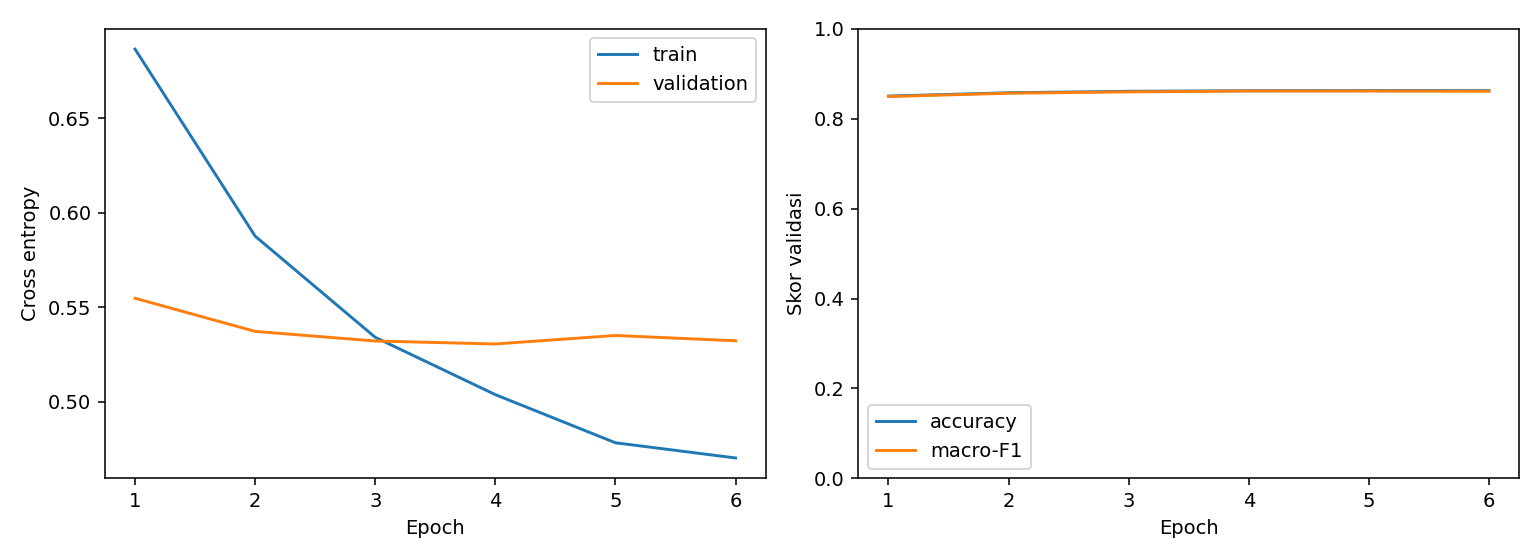

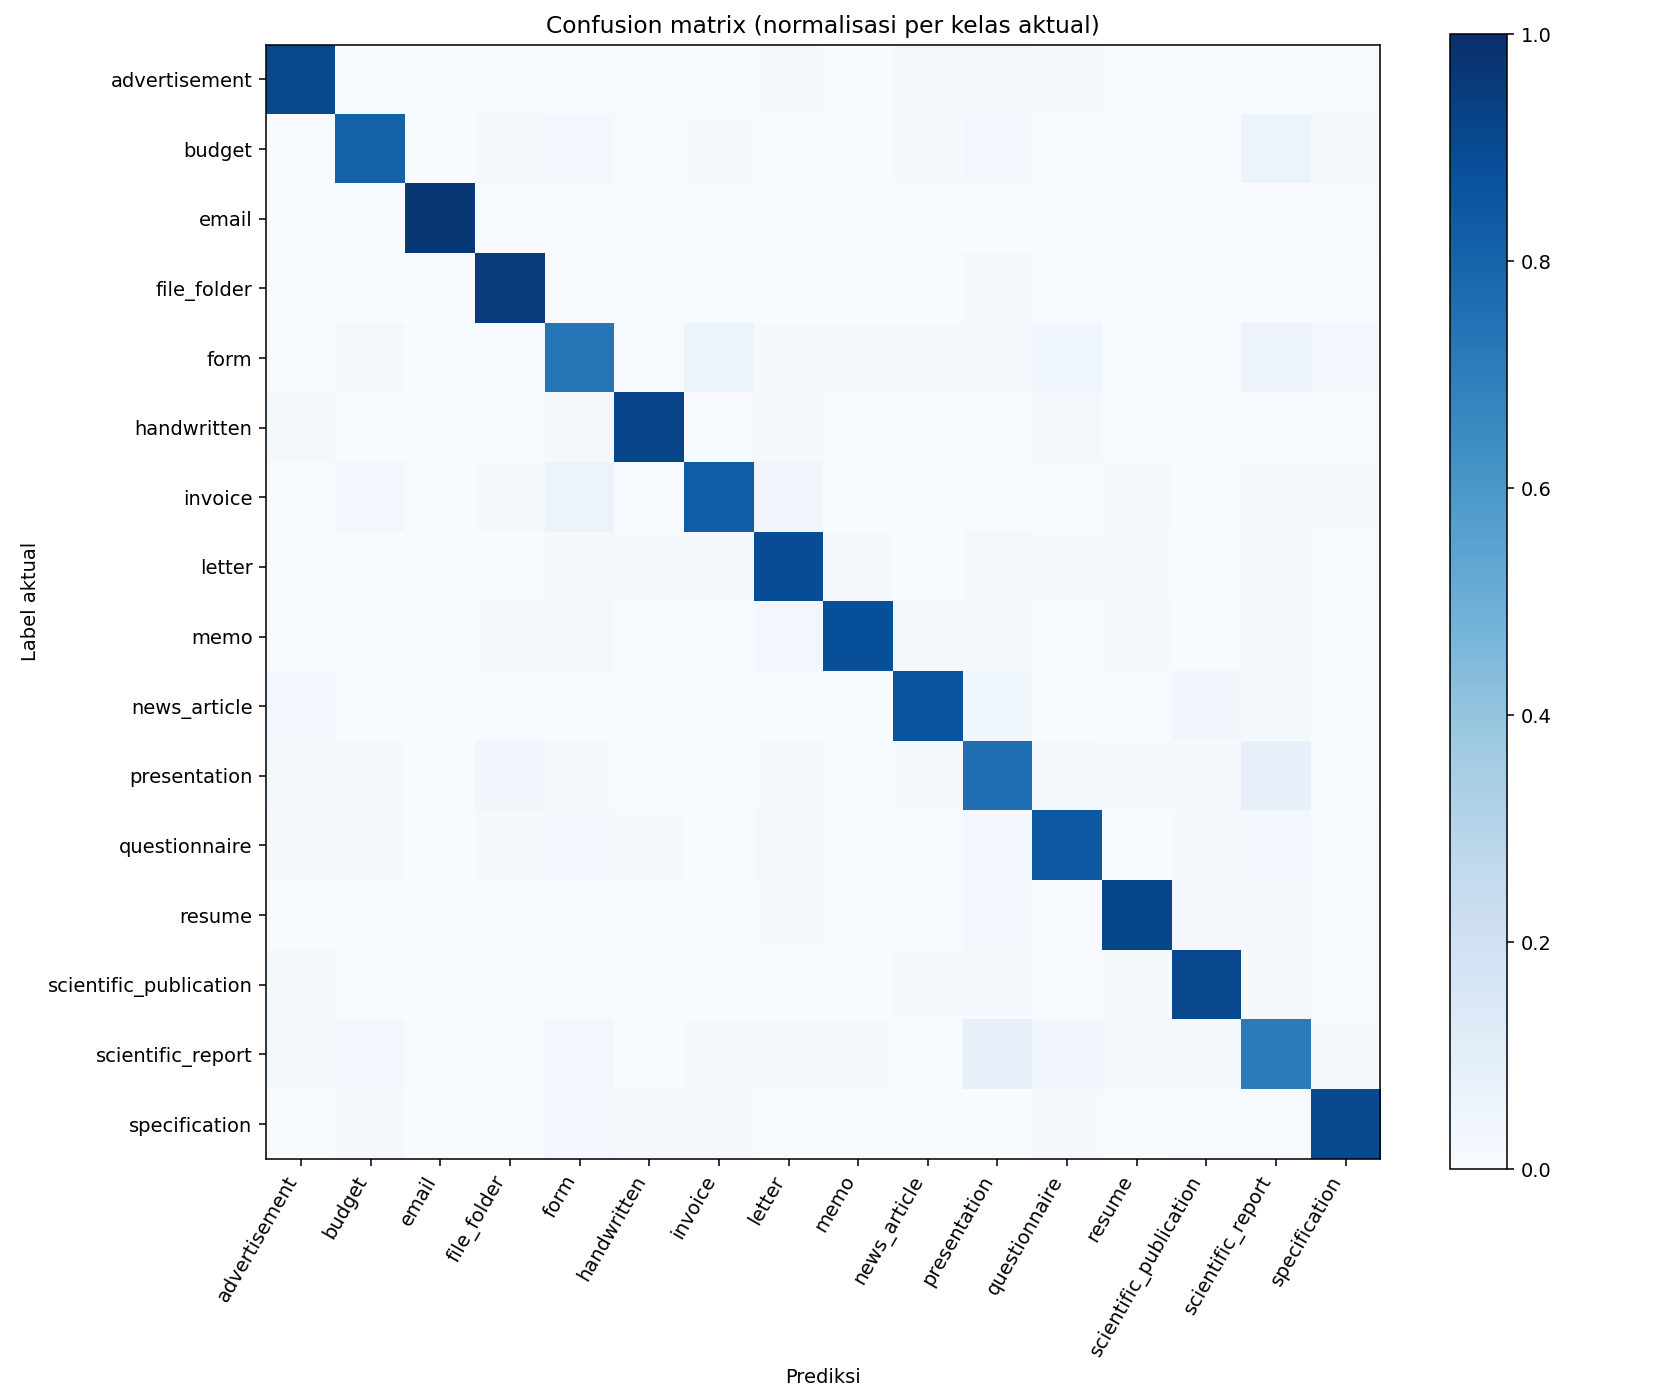

,class_name,baseline_f1,candidate_f1,delta_f1
13,scientific_publication,0.921053,0.902007,-0.019046
15,specification,0.911051,0.893960,-0.017091
12,resume,0.928571,0.912994,-0.015577
5,handwritten,0.933941,0.934857,0.000916
3,file_folder,0.920598,0.923963,0.003365
7,letter,0.857523,0.864935,0.007412
2,email,0.968750,0.977661,0.008911
9,news_article,0.878173,0.888011,0.009838
0,advertisement,0.873762,0.883951,0.010188
11,questionnaire,0.818898,0.829706,0.010808


,id,filename,class_name,label,prediction,predicted_class,confidence
0,train_19275,train/scientific_report/2063596675.tif,scientific_report,14,4,form,0.998006
1,train_10965,train/form/0000977190.tif,form,4,1,budget,0.996974
2,train_06065,train/presentation/0060028964.tif,presentation,10,3,file_folder,0.995844
3,train_08178,train/budget/87629443_87629449.tif,budget,1,14,scientific_report,0.995784
4,train_11150,train/memo/94158557.tif,memo,8,4,form,0.994951
5,train_29439,train/file_folder/0000319200.tif,file_folder,3,11,questionnaire,0.993484
6,train_26090,train/form/2030722680_2030722682.tif,form,4,14,scientific_report,0.993237
7,train_12582,train/scientific_report/1000244855_1000244858.tif,scientific_report,14,6,invoice,0.992975
8,train_02505,train/form/2025042953.tif,form,4,14,scientific_report,0.992936
9,train_22936,train/scientific_report/2028896921-a_202889692...,scientific_report,14,13,scientific_publication,0.992449


In [3]:
display(Image(filename=str(RUN / 'learning_curves.png')))
display(Image(filename=str(RUN / 'confusion_matrix.png')))
display(pd.read_csv(RUN / 'class_comparison.csv').sort_values('delta_f1'))
display(pd.read_csv(RUN / 'confident_errors.csv').head(10))

## Kombinasi dua resolusi
Probabilitas disejajarkan berdasarkan ID. Hash checkpoint pada cache test diverifikasi. Kombinasi 50:50 dibandingkan dengan kedua model tunggal; jika accuracy seri, model tunggal 320 diprioritaskan. Tidak ada pencarian bobot per kelas, penggunaan label test, atau lookup label dari gambar duplikat.

Pemilihan ini menambah penggunaan holdout untuk tuning. Hasil leaderboard harus diperiksa lewat submission baru.

In [4]:
SELECTED = ROOT / 'reports/highres_selection'
selection = json.loads((SELECTED / 'selection.json').read_text())
display(pd.read_csv(SELECTED / 'candidates.csv'))
display(selection)
display(pd.read_csv(SELECTED / 'classification_report.csv', index_col=0))

,variant,weights,accuracy,macro_f1
0,highres_single,"[0.0, 1.0]",0.862392,0.861266
1,previous_single,"[1.0, 0.0]",0.854418,0.853316
2,equal_blend,"[0.5, 0.5]",0.865207,0.864017


{'selection_rule': 'Highest holdout accuracy; ties prefer the highres single model',
 'candidates': [{'variant': 'highres_single',
   'weights': [0.0, 1.0],
   'accuracy': 0.8623924941360438,
   'macro_f1': 0.861266348729832},
  {'variant': 'previous_single',
   'weights': [1.0, 0.0],
   'accuracy': 0.8544175136825645,
   'macro_f1': 0.8533156811409401},
  {'variant': 'equal_blend',
   'weights': [0.5, 0.5],
   'accuracy': 0.8652071931196247,
   'macro_f1': 0.8640173594509721}],
 'selected': {'variant': 'equal_blend',
  'weights': [0.5, 0.5],
  'accuracy': 0.8652071931196247,
  'macro_f1': 0.8640173594509721},
 'validation_rows': 6395,
 'components': [{'run_name': 'efficientnet_improved',
   'checkpoint': 'checkpoint\\efficientnet_improved\\best.pt',
   'checkpoint_sha256': 'd8d9c6d97f01e5d982f182afdeba3b2496b514e062d0e1087dcddfdb153e1e7b'},
  {'run_name': 'efficientnet_highres',
   'checkpoint': 'checkpoint\\efficientnet_highres\\best.pt',
   'checkpoint_sha256': 'e38ff8bd884d1b644197

,precision,recall,f1-score,support
advertisement,0.864734,0.904040,0.883951,396.000000
budget,0.839050,0.817481,0.828125,389.000000
email,0.979058,0.976501,0.977778,383.000000
file_folder,0.897321,0.954869,0.925201,421.000000
form,0.726098,0.753351,0.739474,373.000000
handwritten,0.951724,0.930337,0.940909,445.000000
invoice,0.889855,0.807895,0.846897,380.000000
letter,0.841837,0.882353,0.861619,374.000000
memo,0.939241,0.879147,0.908201,422.000000
news_article,0.904762,0.872449,0.888312,392.000000


## Validasi submission terpilih
Submission yang dipakai adalah `submission_highres_selected.csv`. Dua submission sebelumnya dipertahankan bersama riwayat skor dan hash file masing-masing.

In [5]:
from scripts.preprocess import read_metadata, data_directory
from scripts.predict import validate_submission
output = ROOT / selection['submission']
submission = pd.read_csv(output)
_, test, sample = read_metadata(data_directory())
validate_submission(submission, sample)
assert len(submission) == len(test)
assert hashlib.sha256(output.read_bytes()).hexdigest() == selection['submission_sha256']
print(f'Valid: {len(submission)} rows; variant={selection["selected"]["variant"]}')
display(submission.head())

Valid: 7994 rows; variant=equal_blend


,id,label
0,test_00001,0
1,test_00002,0
2,test_00003,6
3,test_00004,4
4,test_00005,13
